In [13]:
from kafka.admin import KafkaAdminClient, NewTopic

admin = KafkaAdminClient(
    bootstrap_servers="kafka:9092",
)

In [14]:
topic = NewTopic(
    name="weather_stream",
    num_partitions=1,
    replication_factor=1
)

In [19]:
if "weather_stream" not in admin.list_topics():
    admin.create_topics([topic])

In [16]:
from kafka import KafkaProducer
import json

producer = KafkaProducer(
    bootstrap_servers="kafka:9092",
    value_serializer=lambda message: json.dumps(message).encode("utf-8")
)

In [17]:
message = {"msg": "Hello, Kafka"}
producer.send("weather_stream", value=message)
producer.flush()

In [ ]:
from kafka import KafkaConsumer

consumer = KafkaConsumer(
    "weather_stream",
    bootstrap_servers="kafka:9092",
    auto_offset_reset="earliest",
    value_deserializer=lambda message: json.loads(message.decode("utf-8"))
)

for message in consumer:
    print(f"Received message: {message.value}")

Received message: {'msg': 'Hello, Kafka'}
Received message: {'msg': 'Hello, Kafka'}
Received message: {'latitude': 48.853382, 'longitude': 2.355208, 'generationtime_ms': 0.07534027099609375, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 36.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C', 'wind_speed_10m': 'm/s', 'weather_code': 'wmo code'}, 'current': {'time': '2026-11-10T13:45', 'interval': 900, 'temperature_2m': 12.3, 'wind_speed_10m': 1.91, 'weather_code': 80}, 'city': 'Paris', 'country': 'France'}
Received message: {'latitude': 48.853382, 'longitude': 2.355208, 'generationtime_ms': 0.07534027099609375, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 36.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C', 'wind_speed_10m': 'm/s', 'weather_code': 'wmo code'}, 'current': {'time': '2026-11-10T13:45', 'interval': 900, 'temperature_2m

KeyboardInterrupt: 

In [21]:
cities = [
    {
        "city": "Paris",
        "country": "France",
        "latitude": 48.8566,
        "longitude": 2.3522
    },
    {
        "city": "Seville",
        "country": "Spain",
        "latitude": 37.3891,
        "longitude": -5.9845
    },
    {
        "city": "Dubai",
        "country": "United Arab Emirates",
        "latitude": 25.2048,
        "longitude": 55.2708
    },
    {
        "city": "Reykjavik",
        "country": "Iceland",
        "latitude": 64.1466,
        "longitude": -21.9426
    },
    {
        "city": "Wellington",
        "country": "New Zealand",
        "latitude": -41.2865,
        "longitude": 174.7762
    }
]

In [27]:
import requests

#0 c'est paris
city = cities[0]

url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": city["latitude"],
    "longitude": city["longitude"],
    "current": "temperature_2m,wind_speed_10m,weather_code",
    "wind_speed_unit": "ms"
}

response = requests.get(url, params=params, timeout=10)

response.raise_for_status()

print(response.json())

{'latitude': 48.853382, 'longitude': 2.355208, 'generationtime_ms': 0.0756978988647461, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 36.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C', 'wind_speed_10m': 'm/s', 'weather_code': 'wmo code'}, 'current': {'time': '2026-11-10T14:00', 'interval': 900, 'temperature_2m': 12.2, 'wind_speed_10m': 2.05, 'weather_code': 61}}


In [28]:
weather_data = response.json()
weather_data["city"] = city["city"]
weather_data["country"] = city["country"]

producer.send("weather_stream", value=weather_data)
producer.flush()

In [48]:
consumer = KafkaConsumer(
    "weather_stream",
    bootstrap_servers="kafka:9092",
    auto_offset_reset="earliest",
    value_deserializer=lambda message: json.loads(message.decode("utf-8"))
)

for message in consumer:
    print(f"Received message: {message.value}")

Received message: {'msg': 'Hello, Kafka'}
Received message: {'msg': 'Hello, Kafka'}
Received message: {'latitude': 48.853382, 'longitude': 2.355208, 'generationtime_ms': 0.07534027099609375, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 36.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C', 'wind_speed_10m': 'm/s', 'weather_code': 'wmo code'}, 'current': {'time': '2026-11-10T13:45', 'interval': 900, 'temperature_2m': 12.3, 'wind_speed_10m': 1.91, 'weather_code': 80}, 'city': 'Paris', 'country': 'France'}
Received message: {'latitude': 48.853382, 'longitude': 2.355208, 'generationtime_ms': 0.07534027099609375, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 36.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C', 'wind_speed_10m': 'm/s', 'weather_code': 'wmo code'}, 'current': {'time': '2026-11-10T13:45', 'interval': 900, 'temperature_2m

KeyboardInterrupt: 

In [115]:
import time

while True:
    for city in cities:
        params = {
            "latitude": city["latitude"],
            "longitude": city["longitude"],
            "current": "temperature_2m,wind_speed_10m,weather_code",
            "wind_speed_unit": "ms"
        }

        response = requests.get(url, params=params, timeout=10)
        response.raise_for_status()

        weather_data = response.json()
        weather_data["city"] = city["city"]
        weather_data["country"] = city["country"]

        producer.send("weather_stream", value=weather_data)
        print(f"city name : {city['city']}")
    producer.flush()
    time.sleep(30)
    

city name : Paris
city name : Seville
city name : Dubai
city name : Reykjavik
city name : Wellington
city name : Paris
city name : Seville
city name : Dubai
city name : Reykjavik
city name : Wellington
city name : Paris
city name : Seville
city name : Dubai
city name : Reykjavik
city name : Wellington
city name : Paris
city name : Seville
city name : Dubai
city name : Reykjavik
city name : Wellington


KeyboardInterrupt: 

In [53]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("WeatherStreamProcessor") \
    .master("spark://spark-master:7077") \
    .getOrCreate()

In [54]:
kafka_stream = spark.readStream \
    .format("kafka") \
    .option("kafka.bootstrap.servers", "kafka:9092") \
    .option("subscribe", "weather_stream") \
    .option("startingOffsets", "earliest") \
    .load()
    
kafka_stream.printSchema()

root
 |-- key: binary (nullable = true)
 |-- value: binary (nullable = true)
 |-- topic: string (nullable = true)
 |-- partition: integer (nullable = true)
 |-- offset: long (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- timestampType: integer (nullable = true)



In [56]:
raw_stream = kafka_stream.selectExpr("CAST(value AS STRING) AS json", "timestamp AS event_time")

raw_stream.printSchema()


root
 |-- json: string (nullable = true)
 |-- event_time: timestamp (nullable = true)



In [58]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, IntegerType

weather_schema = StructType([
    StructField("city", StringType(), True),
    StructField("country", StringType(), True),
    StructField("current", StructType([
        StructField("temperature_2m", DoubleType(), True),
        StructField("wind_speed_10m", DoubleType(), True),
        StructField("weather_code", IntegerType(), True)
    ]), True)
])

In [61]:
from pyspark.sql.functions import from_json, col

parsed_stream = raw_stream.select(
    col("event_time"), 
    from_json(col("json"), 
    weather_schema).alias("data"))

parsed_stream.printSchema()

root
 |-- event_time: timestamp (nullable = true)
 |-- data: struct (nullable = true)
 |    |-- city: string (nullable = true)
 |    |-- country: string (nullable = true)
 |    |-- current: struct (nullable = true)
 |    |    |-- temperature_2m: double (nullable = true)
 |    |    |-- wind_speed_10m: double (nullable = true)
 |    |    |-- weather_code: integer (nullable = true)



In [63]:
weather_stream = parsed_stream.select(
    col("event_time"),
    col("data.city").alias("city"),
    col("data.country").alias("country"),
    col("data.current.temperature_2m").alias("temperature"),
    col("data.current.wind_speed_10m").alias("windspeed"),
    col("data.current.weather_code").alias("weather_code")
)

weather_stream.printSchema()

root
 |-- event_time: timestamp (nullable = true)
 |-- city: string (nullable = true)
 |-- country: string (nullable = true)
 |-- temperature: double (nullable = true)
 |-- windspeed: double (nullable = true)
 |-- weather_code: integer (nullable = true)



In [126]:
from pyspark.sql.functions import when

weather_alerts = (
    weather_stream
    .withColumn(
        "wind_alert_level",
        when(col("windspeed") < 10, "level_0")
        .when(col("windspeed") <= 20, "level_1")
        .otherwise("level_2")
    )
    .withColumn(
        "heat_alert_level",
        when(col("temperature") < 25, "level_0")
        .when(col("temperature") <= 35, "level_1")
        .otherwise("level_2")
    )
)

weather_alerts.printSchema()


root
 |-- event_time: timestamp (nullable = true)
 |-- city: string (nullable = true)
 |-- country: string (nullable = true)
 |-- temperature: double (nullable = true)
 |-- windspeed: double (nullable = true)
 |-- weather_code: integer (nullable = true)
 |-- wind_alert_level: string (nullable = false)
 |-- heat_alert_level: string (nullable = false)



In [70]:
from pyspark.sql.functions import col, struct, to_json
kafka_output = (
    weather_alerts
    .filter(col("city").isNotNull())
    .select(to_json(struct("*")).alias("value"))
)

kafka_output.printSchema()


root
 |-- value: string (nullable = true)



In [71]:
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

OUTPUT_TOPIC = "weather_transformed"

output_admin = KafkaAdminClient(bootstrap_servers="kafka:9092")
try:
    output_admin.create_topics([
        NewTopic(name=OUTPUT_TOPIC, num_partitions=1, replication_factor=1)
    ])
    print(f"Topic créé : {OUTPUT_TOPIC}")
except TopicAlreadyExistsError:
    print(f"Le topic {OUTPUT_TOPIC} existe déjà, on le réutilise.")
finally:
    output_admin.close()


Topic créé : weather_transformed


In [73]:
weather_query = next(
    (query for query in spark.streams.active if query.name == "weather_transform"),
    None
)

if weather_query is None:
    weather_query = (
        kafka_output.writeStream
        .format("kafka")
        .option("kafka.bootstrap.servers", "kafka:9092")
        .option("topic", OUTPUT_TOPIC)
        .option(
            "checkpointLocation",
            "/home/jovyan/work/checkpoints/weather_transformed"
        )
        .outputMode("append")
        .queryName("weather_transform")
        .start()
    )

print("Requête active :", weather_query.isActive)
print("État :", weather_query.status)
# Pour arrêter le traitement plus tard : weather_query.stop()


Requête active : True
État : {'message': 'Waiting for data to arrive', 'isDataAvailable': False, 'isTriggerActive': False}


In [ ]:
import json
from kafka import KafkaConsumer

check_consumer = KafkaConsumer(
    OUTPUT_TOPIC,
    bootstrap_servers="kafka:9092",
    auto_offset_reset="earliest",
    group_id=None,
    enable_auto_commit=False,
    consumer_timeout_ms=15000,
    value_deserializer=lambda message: json.loads(message.decode("utf-8"))
)

try:
    received = next(check_consumer, None)
    if received is None:
        print("Aucun message reçu en 15 secondes. Vérifie l’état de la requête, puis relance cette cellule.")
    else:
        print(json.dumps(received.value, indent=2, ensure_ascii=False))
finally:
    check_consumer.close()

print("Requête active :", weather_query.isActive)
print("État :", weather_query.status)
query_error = weather_query.exception()
if query_error is not None:
    print("Erreur Spark :", query_error)


{
  "event_time": "2026-11-10T14:03:50.616Z",
  "city": "Paris",
  "country": "France",
  "temperature": 12.3,
  "windspeed": 1.91,
  "weather_code": 80,
  "wind_alert_level": "level_0",
  "heat_alert_level": "level_0"
}
Requête active : True
État : {'message': 'Waiting for data to arrive', 'isDataAvailable': False, 'isTriggerActive': False}


In [104]:
consumer = KafkaConsumer(
    "weather_transformed",
    bootstrap_servers="kafka:9092",
    auto_offset_reset="earliest",
    value_deserializer=lambda message: json.loads(message.decode("utf-8"))
)

for message in consumer:
    print(f"Received message: {message.value}")

Received message: {'event_time': '2026-11-10T14:03:50.616Z', 'city': 'Paris', 'country': 'France', 'temperature': 12.3, 'windspeed': 1.91, 'weather_code': 80, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
Received message: {'event_time': '2026-11-10T14:04:26.491Z', 'city': 'Paris', 'country': 'France', 'temperature': 12.3, 'windspeed': 1.91, 'weather_code': 80, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
Received message: {'event_time': '2026-11-10T14:04:31.604Z', 'city': 'Paris', 'country': 'France', 'temperature': 12.2, 'windspeed': 2.05, 'weather_code': 61, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
Received message: {'event_time': '2026-11-10T14:12:34.593Z', 'city': 'Paris', 'country': 'France', 'temperature': 12.2, 'windspeed': 2.05, 'weather_code': 61, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
Received message: {'event_time': '2026-11-10T14:12:34.901Z', 'city': 'Seville', 'country': 'Spain', 'temperature': 2

KeyboardInterrupt: 

In [106]:
transformed_kafka_stream = spark.readStream \
    .format("kafka") \
    .option("kafka.bootstrap.servers", "kafka:9092") \
    .option("subscribe", "weather_transformed") \
    .option("startingOffsets", "earliest") \
    .load()
transformed_kafka_stream.printSchema()

root
 |-- key: binary (nullable = true)
 |-- value: binary (nullable = true)
 |-- topic: string (nullable = true)
 |-- partition: integer (nullable = true)
 |-- offset: long (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- timestampType: integer (nullable = true)



In [ ]:
from pyspark.sql.types import TimestampType

transformed_schema = StructType([
    StructField("event_time", TimestampType(), True),
    StructField("city", StringType(), True),
    StructField("country", StringType(), True),
    StructField("temperature", DoubleType(), True),
    StructField("windspeed", DoubleType(), True),
    StructField("weather_code", IntegerType(), True),
    StructField("wind_alert_level", StringType(), True),
    StructField("heat_alert_level", StringType(), True)
])


In [110]:
transformed_stream = (
    transformed_kafka_stream
    .selectExpr("CAST(value AS STRING) AS json")
    .select(
        from_json(col("json"), transformed_schema).alias("data")
    )
    .select(
        col("data.event_time").alias("event_time"),
        col("data.city").alias("city"),
        col("data.country").alias("country"),
        col("data.temperature").alias("temperature"),
        col("data.windspeed").alias("windspeed"),
        col("data.weather_code").alias("weather_code"),
        col("data.wind_alert_level").alias("wind_alert_level"),
        col("data.heat_alert_level").alias("heat_alert_level")
    )
)
transformed_stream.printSchema()

root
 |-- event_time: timestamp (nullable = true)
 |-- city: string (nullable = true)
 |-- country: string (nullable = true)
 |-- temperature: double (nullable = true)
 |-- windspeed: double (nullable = true)
 |-- weather_code: integer (nullable = true)
 |-- wind_alert_level: string (nullable = true)
 |-- heat_alert_level: string (nullable = true)



In [111]:
from pyspark.sql.functions import (
    window, col, when, sum as spark_sum, avg,
    min as spark_min, max as spark_max
)

watermarket_stream = (
    transformed_stream
    .withWatermark("event_time", "1 minute")
    .groupBy(
        window(col("event_time"), "1 minute", "30 seconds"),
        col("city"),
        col("country")
    )
    .agg(
        spark_sum(when(col("wind_alert_level") == "level_1", 1).otherwise(0))
            .alias("wind_level_1_count"),
        spark_sum(when(col("wind_alert_level") == "level_2", 1).otherwise(0))
            .alias("wind_level_2_count"),
        spark_sum(when(col("heat_alert_level") == "level_1", 1).otherwise(0))
            .alias("heat_level_1_count"),
        spark_sum(when(col("heat_alert_level") == "level_2", 1).otherwise(0))
            .alias("heat_level_2_count"),
        avg("temperature").alias("avg_temperature"),
        spark_min("temperature").alias("min_temperature"),
        spark_max("temperature").alias("max_temperature"),
        avg("windspeed").alias("avg_windspeed")
    )
    .withColumn(
        "total_alerts",
        col("wind_level_1_count") + col("wind_level_2_count")
        + col("heat_level_1_count") + col("heat_level_2_count")
    )
    .select(
        col("window.start").alias("window_start"),
        col("window.end").alias("window_end"),
        col("city"),
        col("country"),
        col("wind_level_1_count"),
        col("wind_level_2_count"),
        col("heat_level_1_count"),
        col("heat_level_2_count"),
        col("total_alerts"),
        col("avg_temperature"),
        col("min_temperature"),
        col("max_temperature"),
        col("avg_windspeed")
    )
)

watermarket_stream.printSchema()


root
 |-- window_start: timestamp (nullable = true)
 |-- window_end: timestamp (nullable = true)
 |-- city: string (nullable = true)
 |-- country: string (nullable = true)
 |-- wind_level_1_count: long (nullable = true)
 |-- wind_level_2_count: long (nullable = true)
 |-- heat_level_1_count: long (nullable = true)
 |-- heat_level_2_count: long (nullable = true)
 |-- total_alerts: long (nullable = true)
 |-- avg_temperature: double (nullable = true)
 |-- min_temperature: double (nullable = true)
 |-- max_temperature: double (nullable = true)
 |-- avg_windspeed: double (nullable = true)



In [ ]:
aggregates_query = next(
    (query for query in spark.streams.active if query.name == "weather_aggregates_console"),
    None
)

if aggregates_query is None:
    aggregates_query = (
        watermarket_stream.writeStream
        .format("console")
        .outputMode("update")
        .option("truncate", "false")
        .option("numRows", 100)
        .option(
            "checkpointLocation",
            "/home/jovyan/work/checkpoints/weather_aggregates_console"
        )
        .trigger(processingTime="30 seconds")
        .queryName("weather_aggregates_console")
        .start()
    )

print("Agrégats actifs :", aggregates_query.isActive)
print("État :", aggregates_query.status)


Agrégats actifs : True
État : {'message': 'Waiting for next trigger', 'isDataAvailable': False, 'isTriggerActive': False}


In [116]:
consumer = KafkaConsumer(
    "weather_transformed",
    bootstrap_servers="kafka:9092",
    auto_offset_reset="earliest",
    value_deserializer=lambda message: json.loads(message.decode("utf-8"))
)

for message in consumer:
    print(f"Received message: {message.value}")


Received message: {'event_time': '2026-11-10T14:03:50.616Z', 'city': 'Paris', 'country': 'France', 'temperature': 12.3, 'windspeed': 1.91, 'weather_code': 80, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
Received message: {'event_time': '2026-11-10T14:04:26.491Z', 'city': 'Paris', 'country': 'France', 'temperature': 12.3, 'windspeed': 1.91, 'weather_code': 80, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
Received message: {'event_time': '2026-11-10T14:04:31.604Z', 'city': 'Paris', 'country': 'France', 'temperature': 12.2, 'windspeed': 2.05, 'weather_code': 61, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
Received message: {'event_time': '2026-11-10T14:12:34.593Z', 'city': 'Paris', 'country': 'France', 'temperature': 12.2, 'windspeed': 2.05, 'weather_code': 61, 'wind_alert_level': 'level_0', 'heat_alert_level': 'level_0'}
Received message: {'event_time': '2026-11-10T14:12:34.901Z', 'city': 'Seville', 'country': 'Spain', 'temperature': 2

KeyboardInterrupt: 

In [125]:
from kafka import KafkaConsumer
from hdfs import InsecureClient
import json

hdfs_client = InsecureClient("http://namenode:9870", user="root", timeout=(5, 30))

hdfs_consumer = KafkaConsumer(
    "weather_transformed",
    bootstrap_servers="kafka:9092",
    auto_offset_reset="earliest",
    group_id="weather_hdfs",
    enable_auto_commit=False,
    request_timeout_ms=30000,
    value_deserializer=lambda message: json.loads(message.decode("utf-8"))
)

print("En attente des messages Kafka...", flush=True)

try:
    for message in hdfs_consumer:
        weather_data = message.value
        print(f"Message reçu : {weather_data['city']}", flush=True)
        directory = f"/hdfs-data/{weather_data['country']}/{weather_data['city']}"
        file_path = f"{directory}/alerts.json"

        hdfs_client.makedirs(directory)
        file_exists = hdfs_client.status(file_path, strict=False) is not None

        json_line = json.dumps(weather_data, ensure_ascii=False) + "\n"

        if file_exists:
            hdfs_client.set_replication(file_path, 1)
            hdfs_client.write(
                file_path,
                data=json_line,
                encoding="utf-8",
                append=True
            )
        else:
            hdfs_client.write(
                file_path,
                data=json_line,
                encoding="utf-8",
                replication=1,
                overwrite=False
            )

        hdfs_consumer.commit()
        print(f"Message sauvegardé : {file_path}", flush=True)
finally:
    hdfs_consumer.close()

En attente des messages Kafka...
Message reçu : Paris
Message sauvegardé : /hdfs-data/France/Paris/alerts.json
Message reçu : Paris
Message sauvegardé : /hdfs-data/France/Paris/alerts.json
Message reçu : Paris
Message sauvegardé : /hdfs-data/France/Paris/alerts.json
Message reçu : Seville
Message sauvegardé : /hdfs-data/Spain/Seville/alerts.json
Message reçu : Dubai
Message sauvegardé : /hdfs-data/United Arab Emirates/Dubai/alerts.json
Message reçu : Reykjavik
Message sauvegardé : /hdfs-data/Iceland/Reykjavik/alerts.json
Message reçu : Wellington
Message sauvegardé : /hdfs-data/New Zealand/Wellington/alerts.json
Message reçu : Paris
Message sauvegardé : /hdfs-data/France/Paris/alerts.json
Message reçu : Seville
Message sauvegardé : /hdfs-data/Spain/Seville/alerts.json
Message reçu : Dubai
Message sauvegardé : /hdfs-data/United Arab Emirates/Dubai/alerts.json
Message reçu : Reykjavik
Message sauvegardé : /hdfs-data/Iceland/Reykjavik/alerts.json
Message reçu : Wellington
Message sauvegar

KeyboardInterrupt: 

In [128]:
from hdfs import InsecureClient
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

hdfs_client = InsecureClient("http://namenode:9870", user="root", timeout=(5, 30))


In [129]:
weather_logs = []

for directory, folders, files in hdfs_client.walk("/hdfs-data"):
    if "alerts.json" in files:
        with hdfs_client.read(f"{directory}/alerts.json", encoding="utf-8") as reader:
            for line in reader:
                if line.strip():
                    weather_logs.append(json.loads(line))

print(f"{len(weather_logs)} messages chargés depuis HDFS.")


63 messages chargés depuis HDFS.


In [130]:
if not weather_logs:
    raise ValueError("Aucun message météo dans HDFS : exécute d’abord le 6.2.")

weather_df = pd.DataFrame(weather_logs)
weather_df["event_time"] = pd.to_datetime(
    weather_df["event_time"], format="ISO8601", utc=True
)
weather_df = weather_df.sort_values("event_time")
weather_df.head()


,event_time,city,country,temperature,windspeed,weather_code,wind_alert_level,heat_alert_level
0,2026-11-10 14:03:50.616000+00:00,Paris,France,12.3,1.91,80,level_0,level_0
1,2026-11-10 14:04:26.491000+00:00,Paris,France,12.3,1.91,80,level_0,level_0
2,2026-11-10 14:04:31.604000+00:00,Paris,France,12.2,2.05,61,level_0,level_0
3,2026-11-10 14:12:34.593000+00:00,Paris,France,12.2,2.05,61,level_0,level_0
39,2026-11-10 14:12:34.901000+00:00,Seville,Spain,21.4,5.77,80,level_0,level_0


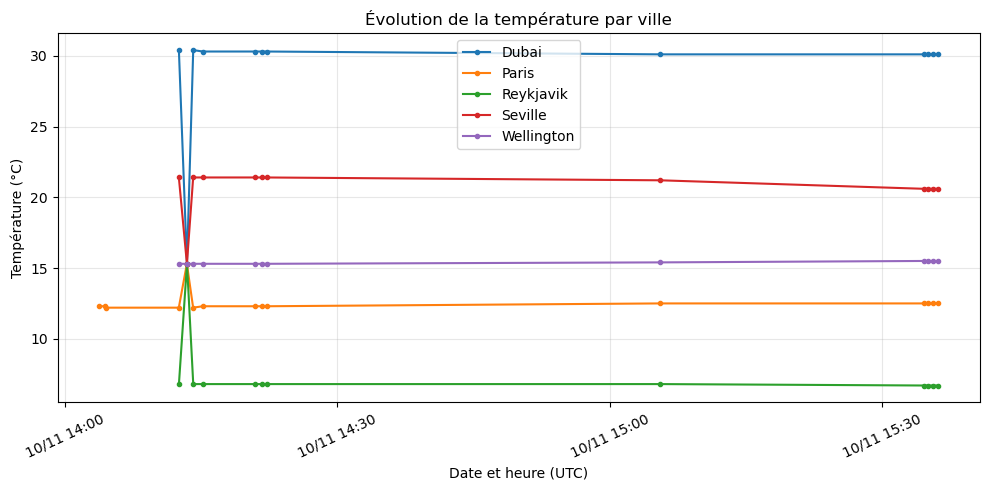

In [131]:
fig, ax = plt.subplots(figsize=(10, 5))

for (city, country), city_data in weather_df.groupby(["city", "country"]):
    ax.plot(city_data["event_time"], city_data["temperature"], marker="o", markersize=3, label=city)

ax.set_title("Évolution de la température par ville")
ax.set_xlabel("Date et heure (UTC)")
ax.set_ylabel("Température (°C)")
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
ax.tick_params(axis="x", rotation=25)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


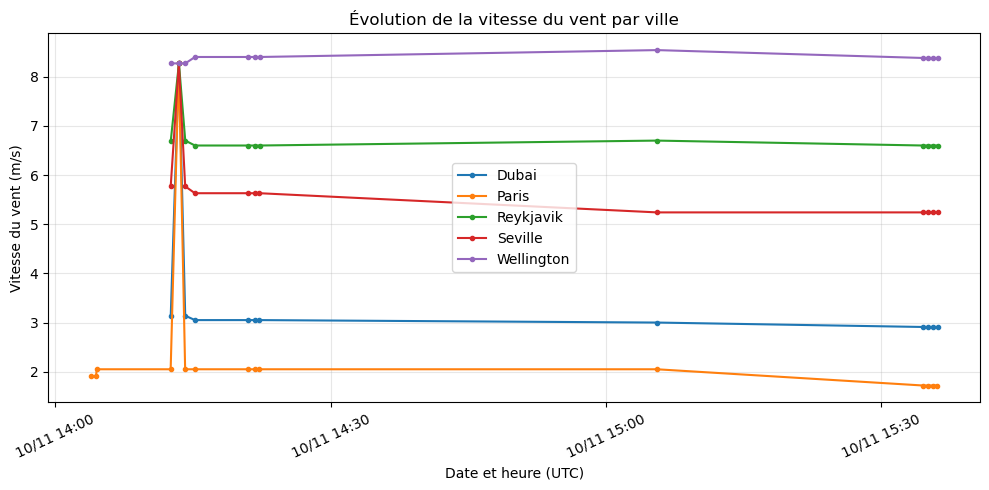

In [132]:
fig, ax = plt.subplots(figsize=(10, 5))

for (city, country), city_data in weather_df.groupby(["city", "country"]):
    ax.plot(city_data["event_time"], city_data["windspeed"], marker="o", markersize=3, label=city)

ax.set_title("Évolution de la vitesse du vent par ville")
ax.set_xlabel("Date et heure (UTC)")
ax.set_ylabel("Vitesse du vent (m/s)")
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
ax.tick_params(axis="x", rotation=25)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [133]:
# level_0 correspond aux relevés sans alerte.
alert_counts = pd.DataFrame({
    "Vent": weather_df["wind_alert_level"].value_counts(),
    "Chaleur": weather_df["heat_alert_level"].value_counts()
}).reindex(["level_0", "level_1", "level_2"]).fillna(0).astype(int)

alert_counts


,Vent,Chaleur
level_0,63,52
level_1,0,11
level_2,0,0


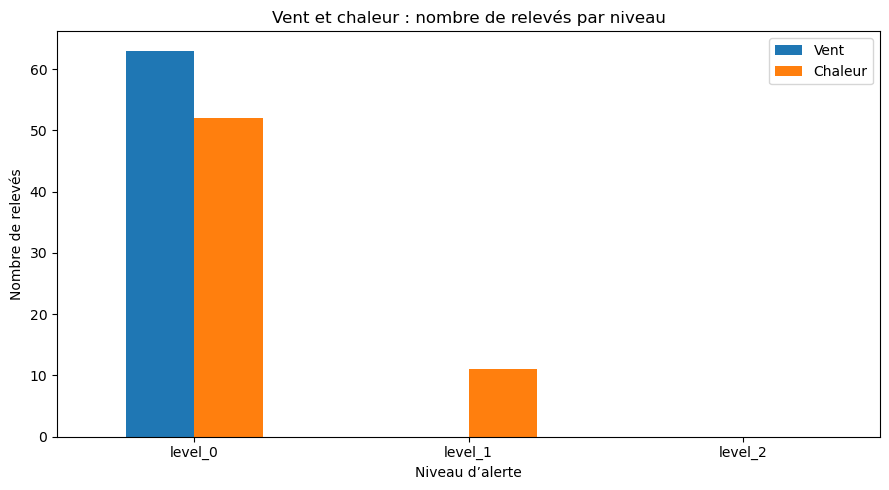

In [134]:
ax = alert_counts.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Vent et chaleur : nombre de relevés par niveau")
ax.set_xlabel("Niveau d’alerte")
ax.set_ylabel("Nombre de relevés")
plt.tight_layout()
plt.show()


In [135]:
code_counts = weather_df.groupby(["country", "weather_code"]).size().reset_index(name="count")

# En cas d’égalité, retenir le plus petit code météo.
dominant_codes = (
    code_counts
    .sort_values(["country", "count", "weather_code"], ascending=[True, False, True])
    .drop_duplicates("country")
)

dominant_codes


,country,weather_code,count
0,France,3,9
6,Iceland,3,6
9,New Zealand,51,8
11,Spain,80,11
12,United Arab Emirates,0,11


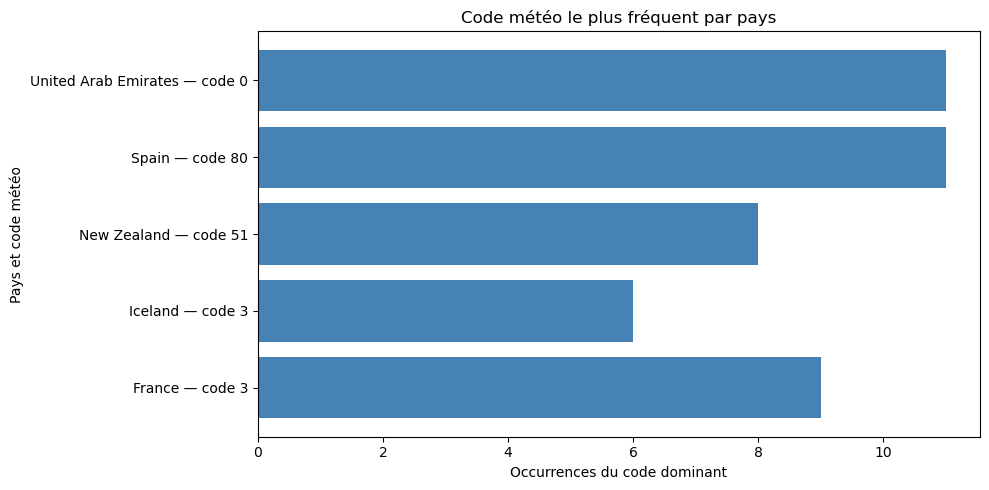

In [136]:
labels = dominant_codes["country"] + " — code " + dominant_codes["weather_code"].astype(int).astype(str)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(labels, dominant_codes["count"], color="steelblue")
ax.set_title("Code météo le plus fréquent par pays")
ax.set_xlabel("Occurrences du code dominant")
ax.set_ylabel("Pays et code météo")
plt.tight_layout()
plt.show()
